round  1 client 0: loss 1.023 acc 0.6533 F1 0.2603
round  1 client 1: loss 1.453 acc 0.4221 F1 0.2539
round  1 client 2: loss 0.877 acc 0.7048 F1 0.3301
round  2 client 0: loss 0.912 acc 0.6533 F1 0.4216
round  2 client 1: loss 0.742 acc 0.7374 F1 0.3788
round  2 client 2: loss 0.783 acc 0.7104 F1 0.4010
round  3 client 0: loss 0.770 acc 0.7186 F1 0.4437
round  3 client 1: loss 0.979 acc 0.6206 F1 0.4299
round  3 client 2: loss 0.714 acc 0.7475 F1 0.4585
round  4 client 0: loss 0.757 acc 0.7136 F1 0.4853
round  4 client 1: loss 1.134 acc 0.6030 F1 0.3998
round  4 client 2: loss 0.827 acc 0.6935 F1 0.5047
round  5 client 0: loss 0.928 acc 0.6369 F1 0.4779
round  5 client 1: loss 0.745 acc 0.7104 F1 0.5296
round  5 client 2: loss 0.702 acc 0.7469 F1 0.5213
round  6 client 0: loss 0.683 acc 0.7412 F1 0.5475
round  6 client 1: loss 0.917 acc 0.6526 F1 0.4451
round  6 client 2: loss 0.788 acc 0.7004 F1 0.5303
round  7 client 0: loss 0.663 acc 0.7569 F1 0.5553
round  7 client 1: loss 0.923 a

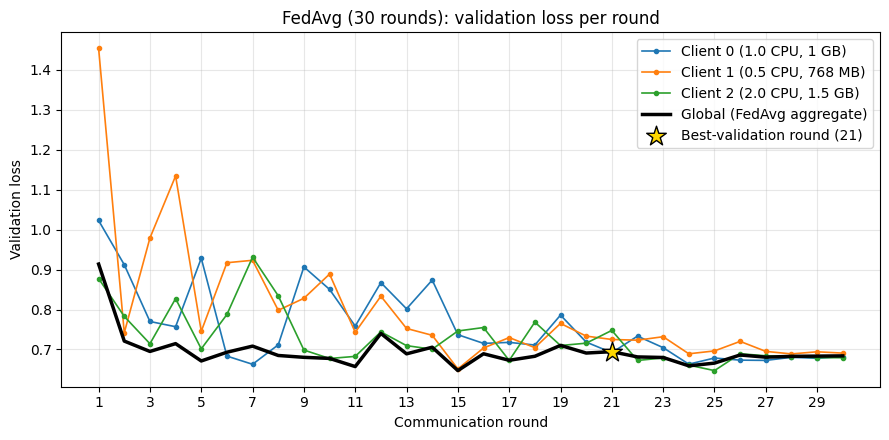

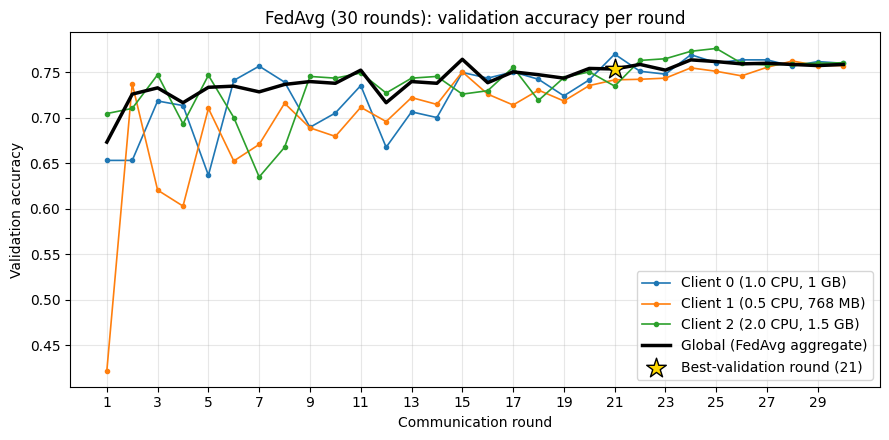

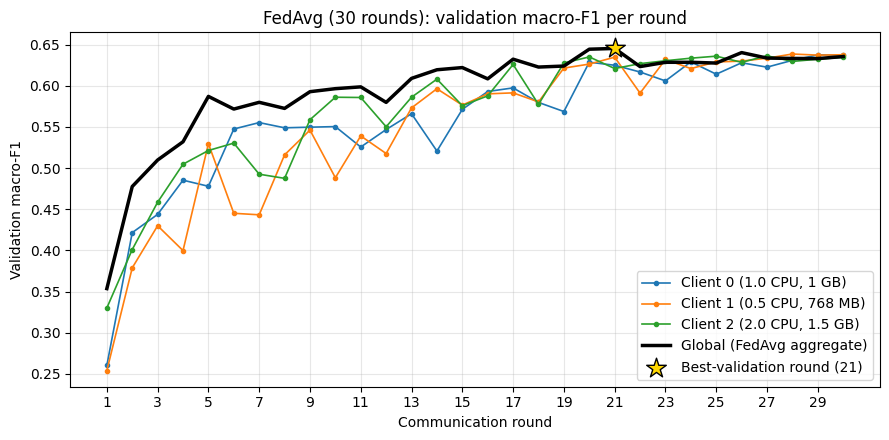


=== Client 0 (1.0 CPU, 1 GB) round 30 | test acc 0.7562 macro-F1 0.5766
              precision    recall  f1-score   support

       akiec       0.44      0.59      0.50        68
         bcc       0.51      0.64      0.57       100
         bkl       0.51      0.56      0.53       205
          df       0.38      0.23      0.29        22
         mel       0.45      0.64      0.53       222
          nv       0.94      0.83      0.88      1363
        vasc       0.74      0.74      0.74        34

    accuracy                           0.76      2014
   macro avg       0.57      0.60      0.58      2014
weighted avg       0.79      0.76      0.77      2014


=== Client 1 (0.5 CPU, 768 MB) round 30 | test acc 0.7532 macro-F1 0.5745
              precision    recall  f1-score   support

       akiec       0.44      0.59      0.51        68
         bcc       0.50      0.64      0.56       100
         bkl       0.49      0.57      0.53       205
          df       0.38      0.23     

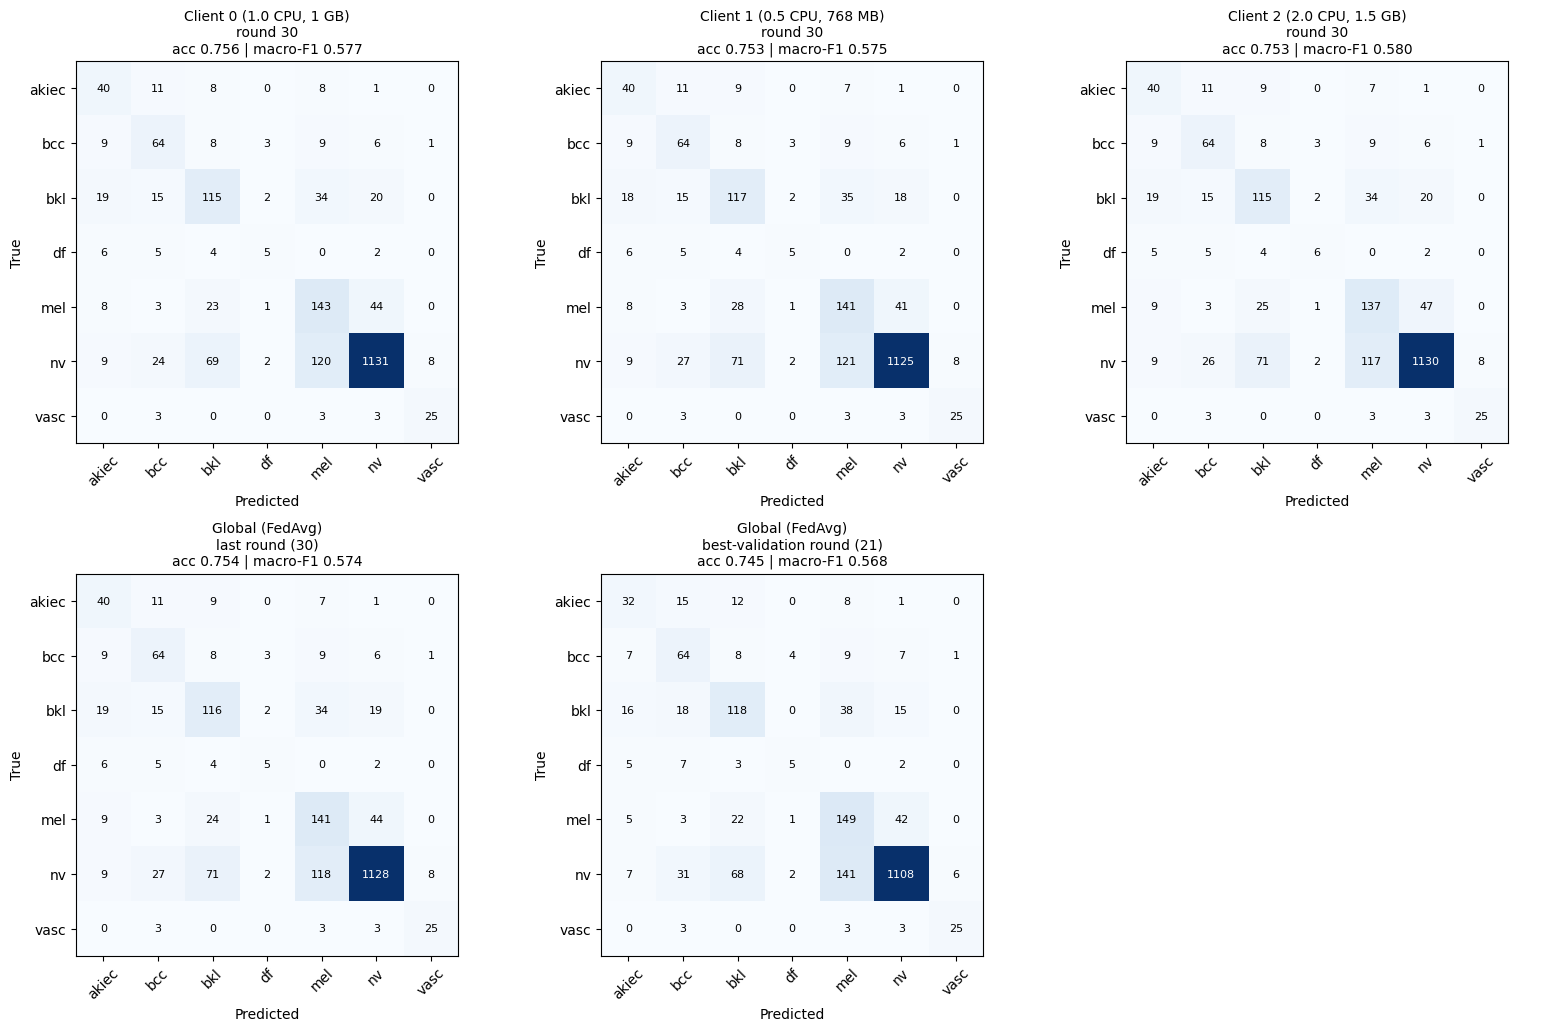

3359

In [4]:
"""
Per-client analysis plots for the aligned 30-round FedAvg baseline.

Run from your "federated learning" folder (the one with dataset/, split_val.csv, split_test.csv,
common.py, shared/ and the output folder of the new run):

    python plot_fl_clients_30.py
    python plot_fl_clients_30.py --out outputs_aligned_seed42 --rounds 30     # explicit paths
(also works when pasted into / run from a Jupyter notebook cell)

IMPORTANT: the server clears shared/ at the start of every run. Run this script (or copy shared/)
BEFORE you start another run or another seed, otherwise the client weights of this run are lost.

Produces
  fl30_loss_per_client.png, fl30_accuracy_per_client.png, fl30_macroF1_per_client.png
      one line per client (own legend entry) + black line for the global model; the star marks
      the round whose global model has the best validation macro-F1 (the one used for testing)
  fl30_confusion_matrices.png
      round-30 model of every client + global (last round) + global (best-validation round)
  fl30_client_eval.csv   per-client, per-round validation metrics (cache; delete to recompute)
  fl30_classification_reports.txt
"""
import os, sys, json, argparse
from pathlib import Path

os.environ.setdefault("DATA_ROOT", ".")           # common.py reads DATA/dataset, DATA/split_*.csv
sys.path.insert(0, ".")

ap = argparse.ArgumentParser()
ap.add_argument("--shared", default="shared")
ap.add_argument("--out", default="outputs_aligned_seed42" if Path("outputs_aligned_seed42").exists() else "outputs_aligned")
ap.add_argument("--rounds", type=int, default=30)
ap.add_argument("--clients", type=int, default=3)
args, _ = ap.parse_known_args()      # known_args so it also runs inside Jupyter (ignores the kernel's -f flag)

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
from common import load_frame, build_model, evaluate, CLASSES

SHARED_DIR, OUT_DIR = Path(args.shared), Path(args.out)
ROUNDS, NUM_CLIENTS = args.rounds, args.clients
HISTORY_CSV = OUT_DIR / "fedavg_history.csv"
FINAL_PTH   = OUT_DIR / "global_final.pth"          # last round
BEST_PTH    = OUT_DIR / "global_best_val.pth"       # best validation macro-F1 round
METRICS     = OUT_DIR / "final_metrics.json"
CACHE       = Path("fl30_client_eval.csv")

CLIENT_NAMES = {0: "Client 0 (1.0 CPU, 1 GB)",
                1: "Client 1 (0.5 CPU, 768 MB)",
                2: "Client 2 (2.0 CPU, 1.5 GB)"}
COLORS = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}
torch.set_num_threads(os.cpu_count())

val_df, test_df = load_frame("split_val.csv"), load_frame("split_test.csv")
model = build_model()

# ---------------- 1) per-client, per-round validation metrics
if CACHE.exists():
    res = pd.read_csv(CACHE)
else:
    rows = []
    for r in range(1, ROUNDS + 1):
        for c in range(NUM_CLIENTS):
            f = SHARED_DIR / f"client{c}_round{r}.pt"
            if not f.exists():
                print("missing", f); continue
            model.load_state_dict(torch.load(f, map_location="cpu")["state"])
            vl, va, vf, _, _ = evaluate(model, val_df)
            rows.append(dict(round=r, client=c, val_loss=vl, val_acc=va, val_macro_f1=vf))
            print(f"round {r:2d} client {c}: loss {vl:.3f} acc {va:.4f} F1 {vf:.4f}", flush=True)
    res = pd.DataFrame(rows)
    res.to_csv(CACHE, index=False)

hist = pd.read_csv(HISTORY_CSV)
best_round = int(hist.loc[hist["val_macro_f1"].idxmax(), "round"])
if METRICS.exists():
    best_round = json.loads(METRICS.read_text())["best_val"]["round"]

def curve(metric, title, ylabel, fname):
    plt.figure(figsize=(9, 4.5))
    for c in range(NUM_CLIENTS):
        d = res[res.client == c]
        plt.plot(d["round"], d[metric], marker="o", ms=3, lw=1.2, color=COLORS[c], label=CLIENT_NAMES[c])
    plt.plot(hist["round"], hist[metric], color="black", lw=2.5, label="Global (FedAvg aggregate)")
    b = hist[hist["round"] == best_round]
    plt.scatter(b["round"], b[metric], marker="*", s=220, color="gold", edgecolor="black", zorder=5,
                label=f"Best-validation round ({best_round})")
    plt.xlabel("Communication round"); plt.ylabel(ylabel); plt.title(title)
    plt.xticks(range(1, ROUNDS + 1, 2)); plt.grid(alpha=.3); plt.legend()
    plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show()

curve("val_loss",     f"FedAvg ({ROUNDS} rounds): validation loss per round",     "Validation loss",     "fl30_loss_per_client.png")
curve("val_acc",      f"FedAvg ({ROUNDS} rounds): validation accuracy per round", "Validation accuracy", "fl30_accuracy_per_client.png")
curve("val_macro_f1", f"FedAvg ({ROUNDS} rounds): validation macro-F1 per round", "Validation macro-F1", "fl30_macroF1_per_client.png")

# ---------------- 2) confusion matrices on the test set
models = {}
for c in range(NUM_CLIENTS):
    sd = torch.load(SHARED_DIR / f"client{c}_round{ROUNDS}.pt", map_location="cpu")["state"]
    models[f"{CLIENT_NAMES[c]}\nround {ROUNDS}"] = sd
if FINAL_PTH.exists():
    models[f"Global (FedAvg)\nlast round ({ROUNDS})"] = torch.load(FINAL_PTH, map_location="cpu")
if BEST_PTH.exists():
    models[f"Global (FedAvg)\nbest-validation round ({best_round})"] = torch.load(BEST_PTH, map_location="cpu")

n = len(models); ncols = 3; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.3 * ncols, 5.2 * nrows))
axes = np.atleast_1d(axes).ravel()
report_txt = []
for ax, (name, sd) in zip(axes, models.items()):
    model.load_state_dict(sd)
    _, acc, f1, preds, labels = evaluate(model, test_df)
    line = f"=== {name.replace(chr(10), ' ')} | test acc {acc:.4f} macro-F1 {f1:.4f}"
    rep = classification_report(labels, preds, target_names=CLASSES, zero_division=0)
    print("\n" + line + "\n" + rep); report_txt.append(line + "\n" + rep)
    cm = confusion_matrix(labels, preds, labels=range(len(CLASSES)))
    ax.imshow(cm, cmap="Blues")
    ax.set_title(f"{name}\nacc {acc:.3f} | macro-F1 {f1:.3f}", fontsize=10)
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=45)
    ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout(); plt.savefig("fl30_confusion_matrices.png", dpi=200); plt.show()
Path("fl30_classification_reports.txt").write_text("\n\n".join(report_txt))